In [53]:
# ============================================
# CELL 1 — Imports
# ============================================
import cdsapi
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import os

print("All imports successful")

All imports successful


In [54]:
# ============================================================
# CELL 2 — Create folders
# ============================================================
os.makedirs("../satellite_data/tropomi", exist_ok=True)
os.makedirs("../satellite_data/era5", exist_ok=True)
os.makedirs("../research/preliminary_results", exist_ok=True)

print("Folders ready:")
print(f"  {os.path.abspath('../satellite_data/tropomi')}")
print(f"  {os.path.abspath('../satellite_data/era5')}")
print(f"  {os.path.abspath('../research/preliminary_results')}")

Folders ready:
  /Users/mqc/Fluxara/fluxara/satellite_data/tropomi
  /Users/mqc/Fluxara/fluxara/satellite_data/era5
  /Users/mqc/Fluxara/fluxara/research/preliminary_results


In [55]:
# ============================================================
# CELL 3 — Connect to Copernicus public S3
# ============================================================

# Imports right here — no dependency on Cell 1
import boto3
from botocore import UNSIGNED
from botocore.config import Config

s3 = boto3.client(
    "s3",
    endpoint_url="https://eodata.dataspace.copernicus.eu",
    config=Config(signature_version=UNSIGNED),
    region_name="default"
)

BUCKET = "eodata"
print("Connected to Copernicus S3 — no login required")

Connected to Copernicus S3 — no login required


In [56]:
import cdsapi, json

client = cdsapi.Client()

# Fetch the dataset schema — shows all valid parameter combinations
try:
    result = client.info("satellite-methane")
    print(json.dumps(result, indent=2))
except Exception as e:
    print(f"Info call failed: {e}")

2026-04-28 20:02:28,806 INFO satellite-methane


null


In [57]:
pip install sentinelsat requests

Note: you may need to restart the kernel to use updated packages.


In [58]:
import requests
from pathlib import Path
import os

# ── Search — no login needed ─────────────────────────────────
YEAR  = 2024
MONTH = 6
DAY   = 1

url = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products"
params = {
    "$filter": (
        "Collection/Name eq 'SENTINEL-5P' and "
        "Attributes/OData.CSC.StringAttribute/any("
        "att:att/Name eq 'productType' and "
        "att/OData.CSC.StringAttribute/Value eq 'L2__CH4___') and "
        f"ContentDate/Start gt {YEAR}-{MONTH:02d}-{DAY:02d}T00:00:00.000Z and "
        f"ContentDate/Start lt {YEAR}-{MONTH:02d}-{DAY:02d}T23:59:59.000Z"
    ),
    "$orderby": "ContentDate/Start asc",
    "$top": 10,
}

r = requests.get(url, params=params, timeout=30)
print("Search status:", r.status_code)

products = r.json().get("value", [])
print(f"Found {len(products)} products:\n")
for i, p in enumerate(products):
    size_mb = round(p.get("ContentLength", 0) / 1e6, 1)
    print(f"  [{i}]  {size_mb:6.1f} MB  —  {p['Name'][:60]}")
    print(f"        ID: {p['Id']}")

Search status: 200
Found 10 products:

  [0]    40.6 MB  —  S5P_OFFL_L2__CH4____20240601T002118_20240601T020248_34371_03
        ID: 44c8a672-405a-4097-9b2d-526296f297d1
  [1]    43.7 MB  —  S5P_OFFL_L2__CH4____20240601T020248_20240601T034417_34372_03
        ID: a1a367fd-d113-4bf3-8486-97e8d379c4f0
  [2]    54.8 MB  —  S5P_OFFL_L2__CH4____20240601T034417_20240601T052547_34373_03
        ID: c10e4436-f3bb-471e-bf15-59923304d434
  [3]    49.0 MB  —  S5P_OFFL_L2__CH4____20240601T052547_20240601T070717_34374_03
        ID: bda24213-2265-4013-bd13-4463bb7b5a6d
  [4]    53.6 MB  —  S5P_OFFL_L2__CH4____20240601T070717_20240601T084847_34375_03
        ID: 37c8e14d-6105-46dd-be0c-870233bf59af
  [5]    60.7 MB  —  S5P_OFFL_L2__CH4____20240601T084847_20240601T103017_34376_03
        ID: 7f33ffe9-5086-44dc-88b4-2308cf64a2e5
  [6]    66.2 MB  —  S5P_OFFL_L2__CH4____20240601T103017_20240601T121147_34377_03
        ID: 5f481842-c76a-4847-8353-f96661ca0a21
  [7]    65.0 MB  —  S5P_OFFL_L2__CH4____202

In [59]:
# Register free at https://dataspace.copernicus.eu  ← do this first
# Takes 2 minutes, verify  email, then come back here

CDSE_USER = "baburambastola716@gmail.com"    # ← put  actual email
CDSE_PASS = "3Poush2059@@"           # ← put actual password

def get_token(user, password):
    r = requests.post(
        "https://identity.dataspace.copernicus.eu/auth/realms/CDSE"
        "/protocol/openid-connect/token",
        data={
            "client_id":  "cdse-public",
            "grant_type": "password",
            "username":   user,
            "password":   password,
        },
        timeout=30
    )
    if not r.ok:
        print("Auth failed. Response:", r.text)
        raise Exception(f"Token error: {r.status_code}")
    return r.json()["access_token"]

token = get_token(CDSE_USER, CDSE_PASS)
print("Token acquired:", token[:40], "...")
print("Valid for 10 minutes — re-run this cell if download fails with 401")

Token acquired: eyJhbGciOiJSUzI1NiIsInR5cCIgOiAiSldUIiwi ...
Valid for 10 minutes — re-run this cell if download fails with 401


In [60]:
PRODUCT_INDEX = 0   # ← change to try a different orbit

chosen   = products[PRODUCT_INDEX]
save_dir = Path("../satellite_data/tropomi")
save_dir.mkdir(parents=True, exist_ok=True)
out_path = save_dir / f"{chosen['Name']}.nc"

if out_path.exists():
    print(f"Already downloaded: {out_path.name}")
else:
    download_url = (
        f"https://download.dataspace.copernicus.eu"
        f"/odata/v1/Products({chosen['Id']})/$value"
    )
    print(f"Downloading {round(chosen.get('ContentLength',0)/1e6,1)} MB...")
    print(f"URL: {download_url}\n")

    headers   = {"Authorization": f"Bearer {token}"}
    done      = [0]
    total     = chosen.get("ContentLength", 1)

    with requests.get(download_url, headers=headers,
                      stream=True, timeout=120) as r:
        if r.status_code == 401:
            print("Token expired — re-run Cell 4 to get a new token")
            raise Exception("401 Unauthorized")
        r.raise_for_status()

        with open(out_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                f.write(chunk)
                done[0] += len(chunk)
                pct = done[0] / total * 100
                print(f"\r  {pct:.1f}%  ({done[0]/1e6:.1f} MB)", end="", flush=True)

    print(f"\n\nSaved: {out_path}")
    print(f"Size:  {out_path.stat().st_size / 1e6:.1f} MB")

URL: https://download.dataspace.copernicus.eu/odata/v1/Products(44c8a672-405a-4097-9b2d-526296f297d1)/$value

  100.0%  (40.6 MB)

Saved: ../satellite_data/tropomi/S5P_OFFL_L2__CH4____20240601T002118_20240601T020248_34371_03_020600_20240606T165112.nc.nc
Size:  40.6 MB


Opening: S5P_OFFL_L2__CH4____20240601T002118_20240601T020248_34371_03_020600_20240606T165112.nc.nc
Valid pixels:  11,360
CH4 mean:      1880.6 ppb
CH4 max:       1956.0 ppb


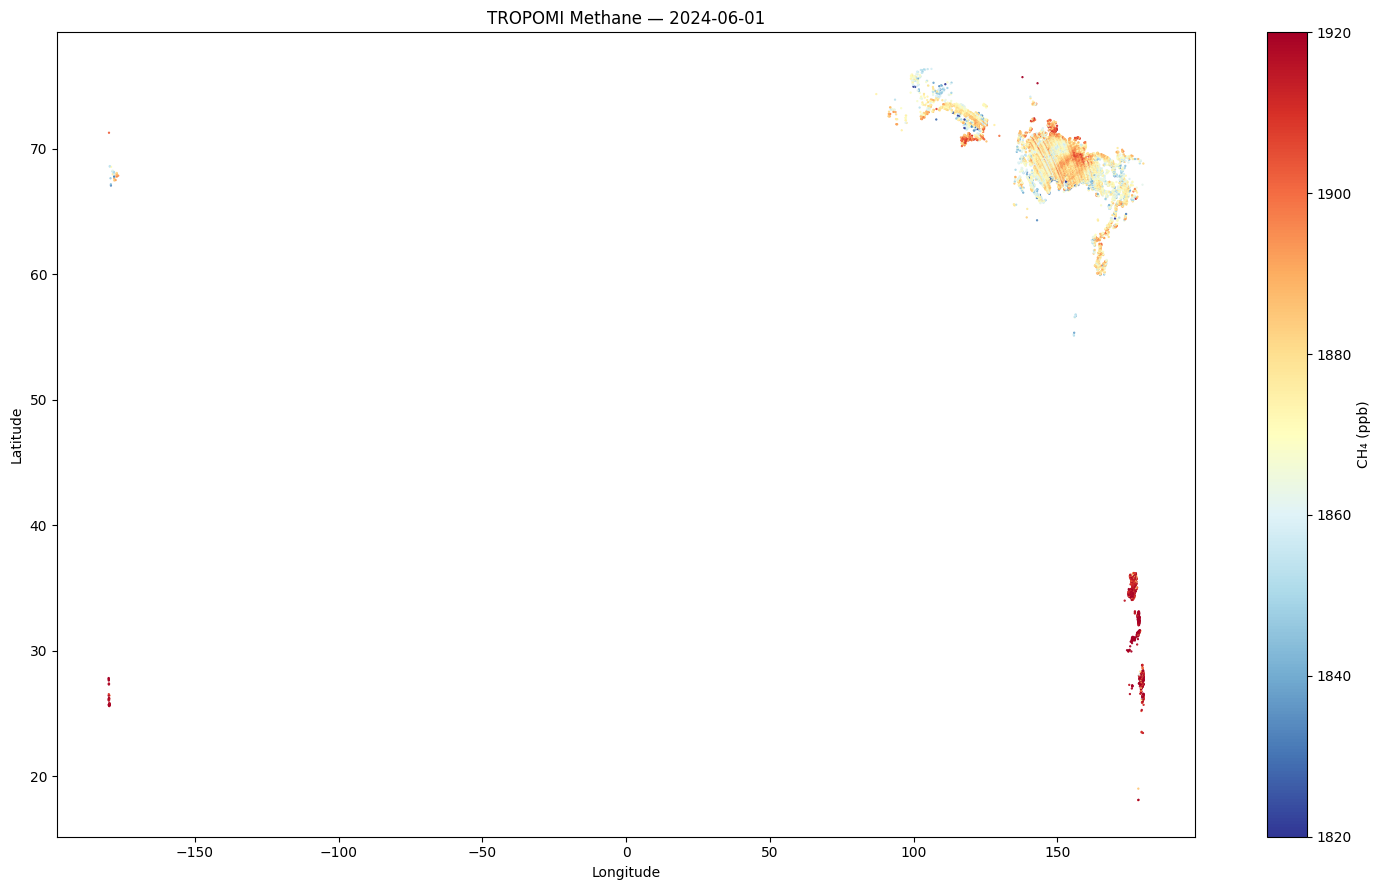

Plot saved.


In [69]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

print(f"Opening: {out_path.name}")

ds  = xr.open_dataset(out_path, group="PRODUCT", engine="netcdf4")
ch4 = ds["methane_mixing_ratio_bias_corrected"].values.squeeze()
qa  = ds["qa_value"].values.squeeze()
lat = ds["latitude"].values.squeeze()
lon = ds["longitude"].values.squeeze()

mask = qa >= 0.5

print(f"Valid pixels:  {mask.sum():,}")
print(f"CH4 mean:      {np.nanmean(ch4[mask]):.1f} ppb")
print(f"CH4 max:       {np.nanmax(ch4[mask]):.1f} ppb")

plt.figure(figsize=(15,9))
plt.scatter(lon[mask], lat[mask], c=ch4[mask],
            s=0.4, cmap="RdYlBu_r", vmin=1820, vmax=1920)
plt.colorbar(label="CH₄ (ppb)")
plt.title(f"TROPOMI Methane — {YEAR}-{MONTH:02d}-{DAY:02d}")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.tight_layout()
plt.savefig("../research/preliminary_results/first_satellite_plot.png", dpi=150)
plt.show()
print("Plot saved.")

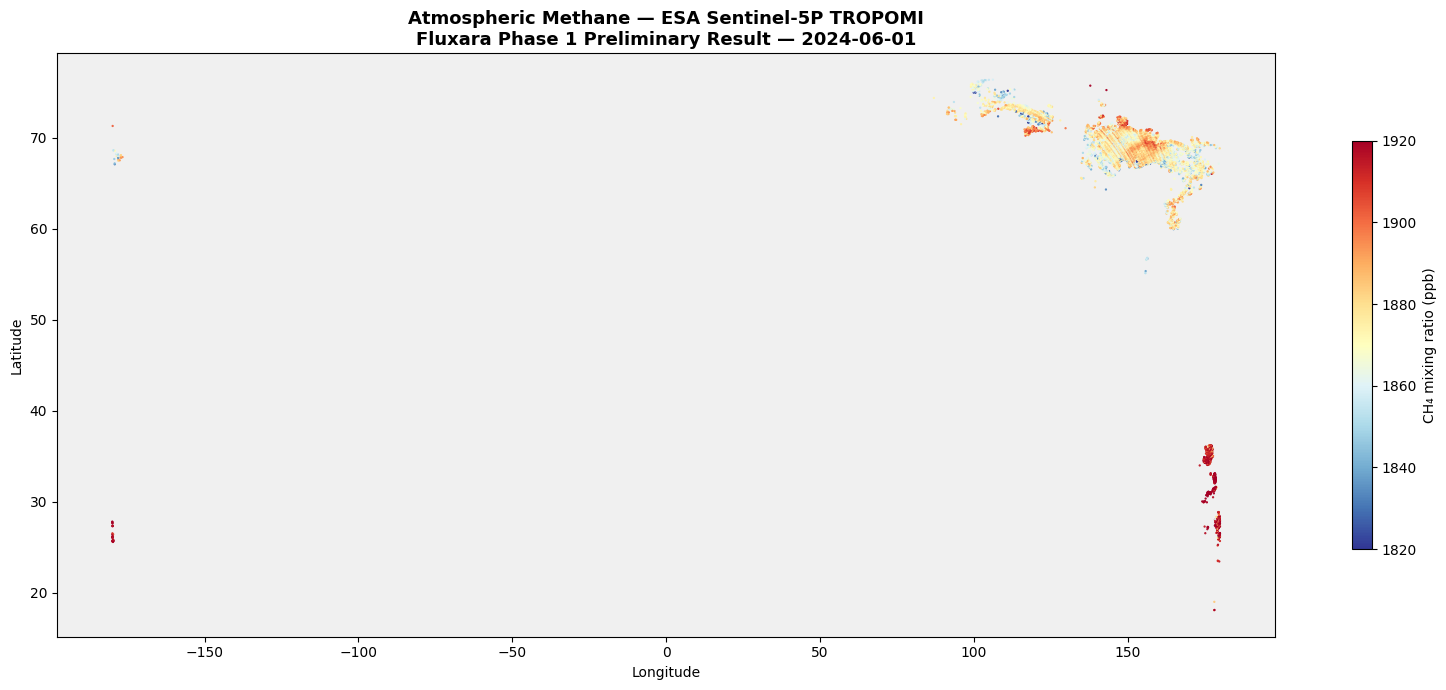

Saved: ../research/preliminary_results/first_satellite_plot.png


In [70]:
# ============================================
# CELL 7— Plot anomalies only
# ============================================
fig, ax = plt.subplots(figsize=(16, 7))

sc = ax.scatter(
    lon[mask], lat[mask],
    c=ch4[mask],
    s=0.4,
    cmap="RdYlBu_r",
    vmin=1820,
    vmax=1920
)
plt.colorbar(sc, ax=ax, label="CH₄ mixing ratio (ppb)", shrink=0.7)
ax.set_facecolor("#f0f0f0")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(
    f"Atmospheric Methane — ESA Sentinel-5P TROPOMI\n"
    f"Fluxara Phase 1 Preliminary Result — {YEAR}-{MONTH:02d}-{DAY:02d}",
    fontsize=13, fontweight="bold"
)
plt.tight_layout()

save_path = "../research/preliminary_results/first_satellite_plot.png"
Path("../research/preliminary_results").mkdir(parents=True, exist_ok=True)
plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {save_path}")

In [71]:
# ============================================
# CELL 8 — Download ERA5 wind data
# You need this for the inversion model
# Takes 5 minutes
# ============================================
# Flatten and clean
ch4_clean = ch4[mask].flatten()
ch4_clean = ch4_clean[~np.isnan(ch4_clean)]

mean      = ch4_clean.mean()
std       = ch4_clean.std()
threshold = mean + (2 * std)

print(f"Global mean:       {mean:.1f} ppb")
print(f"Std deviation:     {std:.1f} ppb")
print(f"Anomaly threshold: {threshold:.1f} ppb  (mean + 2 standard deviations)")

anomaly_mask = mask & (ch4 > threshold)
print(f"\nTotal valid pixels:   {mask.sum():,}")
print(f"Anomaly pixels:       {anomaly_mask.sum():,}")
print(f"Anomaly fraction:     {anomaly_mask.sum()/mask.sum()*100:.2f}%")

# Top 10 hotspot locations
anom_lats = lat[anomaly_mask]
anom_lons = lon[anomaly_mask]
anom_vals = ch4[anomaly_mask]
top_idx   = np.argsort(anom_vals)[::-1][:10]

print(f"\nTop 10 highest CH4 locations:")
print(f"{'#':<4} {'Latitude':>10} {'Longitude':>11} {'CH4 (ppb)':>10}")
print("-" * 40)
for rank, i in enumerate(top_idx):
    print(f"{rank+1:<4} {anom_lats[i]:>10.3f} {anom_lons[i]:>11.3f} {anom_vals[i]:>10.1f}")

Global mean:       1880.6 ppb
Std deviation:     18.6 ppb
Anomaly threshold: 1917.7 ppb  (mean + 2 standard deviations)

Total valid pixels:   11,360
Anomaly pixels:       686
Anomaly fraction:     6.04%

Top 10 highest CH4 locations:
#      Latitude   Longitude  CH4 (ppb)
----------------------------------------
1        31.007     176.113     1956.0
2        30.812     176.174     1954.5
3        30.910     176.143     1954.2
4        30.894     176.658     1953.8
5        30.861     176.158     1952.5
6        30.958     176.128     1952.2
7        31.101     176.256     1952.2
8        27.164     176.121     1949.9
9        30.716     175.489     1949.4
10       31.056     176.098     1948.9


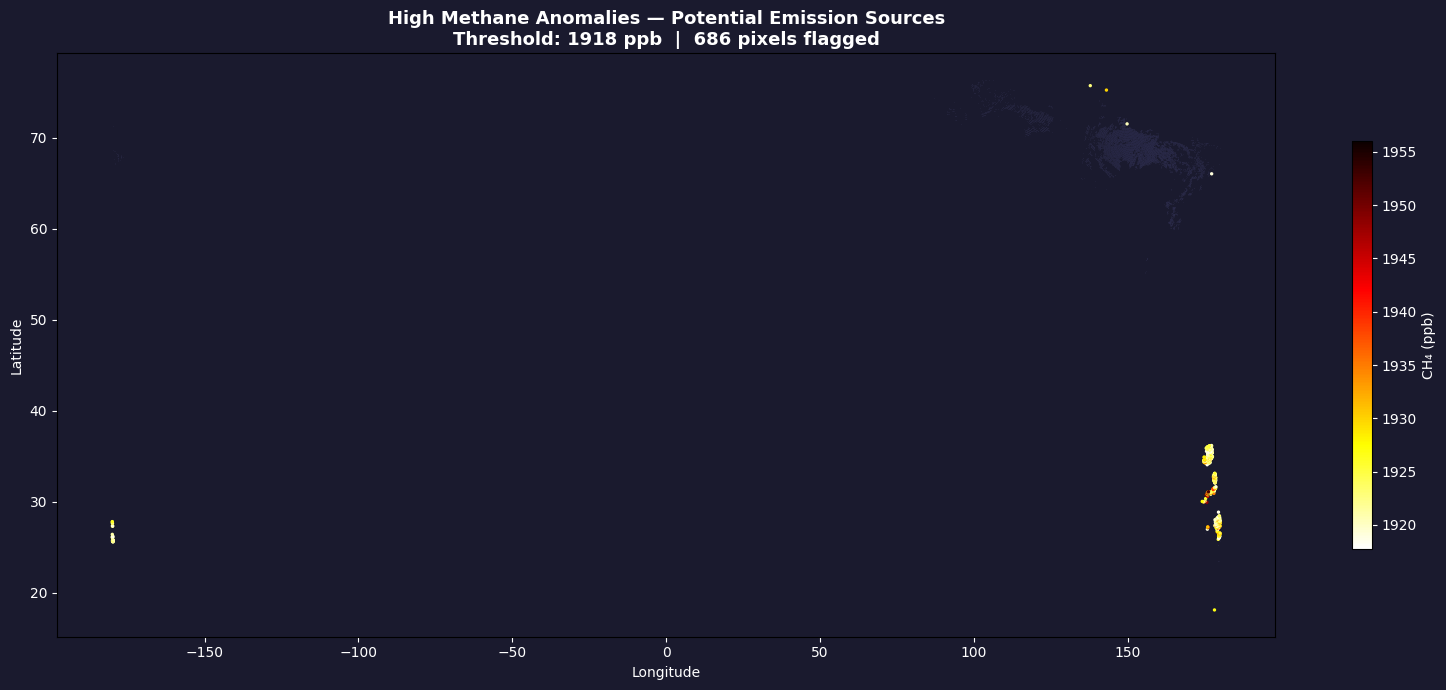

Saved: ../research/preliminary_results/methane_anomalies.png
Bright spots = candidate emission sources for Fluxara inversion pipeline


In [72]:
# ============================================
# CELL 9 — Load and plot wind data
# ============================================

fig, ax = plt.subplots(figsize=(16, 7))
fig.patch.set_facecolor("#1a1a2e")
ax.set_facecolor("#1a1a2e")

# Background — all valid pixels in muted gray
ax.scatter(lon[mask], lat[mask],
           c="#333355", s=0.2, alpha=0.4, linewidths=0)

# Anomalies in hot colormap
sc = ax.scatter(
    lon[anomaly_mask], lat[anomaly_mask],
    c=ch4[anomaly_mask],
    s=2,
    cmap="hot_r",
    vmin=threshold,
    vmax=float(np.nanmax(ch4[anomaly_mask]))
)

cbar = plt.colorbar(sc, ax=ax, label="CH₄ (ppb)", shrink=0.7)
cbar.ax.yaxis.label.set_color("white")
cbar.ax.tick_params(colors="white")

ax.set_xlabel("Longitude", color="white")
ax.set_ylabel("Latitude", color="white")
ax.tick_params(colors="white")
ax.set_title(
    f"High Methane Anomalies — Potential Emission Sources\n"
    f"Threshold: {threshold:.0f} ppb  |  {anomaly_mask.sum():,} pixels flagged",
    fontsize=13, fontweight="bold", color="white"
)

plt.tight_layout()
save_path = "../research/preliminary_results/methane_anomalies.png"
plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {save_path}")
print("Bright spots = candidate emission sources for Fluxara inversion pipeline")

In [73]:
# ============================================
# CELL 10
# ============================================
# Change these coordinates to zoom into any region you want
LON_MIN, LON_MAX = -105, -98
LAT_MIN, LAT_MAX =   29,  35
REGION_NAME      = "Permian Basin, West Texas"

region_mask = (
    mask
    & (lon >= LON_MIN) & (lon <= LON_MAX)
    & (lat >= LAT_MIN) & (lat <= LAT_MAX)
)

print(f"Region: {REGION_NAME}")
print(f"Pixels in region: {region_mask.sum():,}")

if region_mask.sum() == 0:
    print("\nNo data in this region for this orbit.")
    print("TROPOMI covers the globe in ~14 orbital strips per day.")
    print("Try PRODUCT_INDEX = 1, 2, 3 in Cell 5 and re-download.")
else:
    region_ch4 = ch4[region_mask]
    print(f"CH4 mean in region: {np.nanmean(region_ch4):.1f} ppb")
    print(f"CH4 max in region:  {np.nanmax(region_ch4):.1f} ppb")

    region_anomaly = region_mask & (ch4 > threshold)
    print(f"Anomaly pixels:     {region_anomaly.sum():,}")

    fig, ax = plt.subplots(figsize=(11, 8))

    sc = ax.scatter(
        lon[region_mask], lat[region_mask],
        c=ch4[region_mask],
        s=10,
        cmap="RdYlBu_r",
        vmin=1830,
        vmax=1920
    )
    plt.colorbar(sc, ax=ax, label="CH₄ (ppb)")

    # Red rings around anomalies
    if region_anomaly.sum() > 0:
        ax.scatter(
            lon[region_anomaly], lat[region_anomaly],
            s=40, facecolors="none", edgecolors="red",
            linewidths=1.2, label=f"Anomaly > {threshold:.0f} ppb",
            zorder=5
        )
        ax.legend(fontsize=10)

    ax.set_xlim(LON_MIN, LON_MAX)
    ax.set_ylim(LAT_MIN, LAT_MAX)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(
        f"TROPOMI CH₄ — {REGION_NAME}\n{YEAR}-{MONTH:02d}-{DAY:02d}",
        fontsize=13, fontweight="bold"
    )
    ax.grid(True, alpha=0.3)

    save_path = "../research/preliminary_results/region_zoom.png"
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {save_path}")

Region: Permian Basin, West Texas
Pixels in region: 0

No data in this region for this orbit.
TROPOMI covers the globe in ~14 orbital strips per day.
Try PRODUCT_INDEX = 1, 2, 3 in Cell 5 and re-download.


In [ ]:
# # cell 11

# # ERA5 still works fine through CDS
# # Register at: https://cds.climate.copernicus.eu
# # Then run: pip install cdsapi  and configure ~/.cdsapirc

# import cdsapi

# cds = cdsapi.Client()

# cds.retrieve(
#     "reanalysis-era5-pressure-levels",
#     {
#         "product_type": "reanalysis",
#         "variable": [
#             "u_component_of_wind",
#             "v_component_of_wind",
#             "temperature",
#             "geopotential",
#         ],
#         "pressure_level": ["850", "700", "500"],
#         "year":  str(YEAR),
#         "month": f"{MONTH:02d}",
#         "day":   [f"{DAY:02d}"],
#         "time":  ["00:00", "06:00", "12:00", "18:00"],
#         "format": "netcdf",
#     },
#     "../satellite_data/era5/wind_june2024.nc",
# )

# print("ERA5 wind data downloaded")


import cdsapi
from pathlib import Path

# Defined here directly so this cell runs standalone
YEAR  = 2024
MONTH = 6
DAY   = 1

Path("../satellite_data/era5").mkdir(parents=True, exist_ok=True)

cds = cdsapi.Client()

cds.retrieve(
    "reanalysis-era5-pressure-levels",
    {
        "product_type": "reanalysis",
        "variable": [
            "u_component_of_wind",
            "v_component_of_wind",
            "temperature",
            "geopotential",
        ],
        "pressure_level": ["850", "700", "500"],
        "year":  str(YEAR),
        "month": f"{MONTH:02d}",
        "day":   [f"{DAY:02d}"],
        "time":  ["00:00", "06:00", "12:00", "18:00"],
        "format": "netcdf",
    },
    "../satellite_data/era5/wind_june2024.nc",   # plain filename — no hyperlink
)

print("ERA5 wind data downloaded")
print(f"Saved to: ../satellite_data/era5/wind_june2024.nc")

2026-04-28 20:21:29,538 INFO Request ID is 1120387b-aad8-48a8-9b00-55bfacfb5d3b
2026-04-28 20:21:29,629 INFO status has been updated to accepted


KeyboardInterrupt: 

In [ ]:
# 

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

wind = xr.open_dataset("../satellite_data/era5/wind_june2024.nc")

print("ERA5 variables:", list(wind.data_vars))
print("Dimensions:", dict(wind.dims))
print("Times available:", wind.time.values)
print("Pressure levels:", wind.pressure_level.values)